In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from wordcloud import WordCloud

TEXT_COL = "text_clean"
N_TOP = 10
N_WORDS = 100


sns.set_style("white")

In [ ]:
def top_words_per_cluster(df, k, text_col = TEXT_COL, n_top = N_TOP):
    texts = df[text_col].fillna("")

    vectorizer = CountVectorizer(min_df=5, max_df=0.5)
    X = vectorizer.fit_transform(texts)
    vocab = np.array(vectorizer.get_feature_names_out())

    labels = df["cluster"].to_numpy()
    result = {}
    for c in range(k):
        counts = np.asarray(X[labels == c].sum(axis=0)).ravel()
        idx = counts.argsort()[::-1][:n_top]
        result[c] = (vocab[idx], counts[idx])
    return result


def plot_top_words(df, top, k, n_cols=3):
    palette = sns.color_palette("tab10", n_colors=k)
    n_rows = int(np.ceil(k / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.2 * n_rows))
    axes = np.atleast_1d(axes).ravel()

    for c in range(k):
        words, counts = top[c]
        n_docs = (df["cluster"] == c).sum()
        axes[c].barh(words[::-1], counts[::-1], color=palette[c], alpha=0.8)
        axes[c].set_title(f"cluster {c} (n={n_docs})", loc="left", fontsize=11)
        axes[c].set_xlabel("word count")
        sns.despine(ax=axes[c])

    for ax in axes[k:]:
        ax.axis("off")

    fig.suptitle(f"arXiv abstracts: top {N_TOP} words per cluster (k={k})",
                 x=0.01, ha="left", fontsize=13)
    plt.tight_layout(rect=(0, 0, 1, 0.95))
    return fig

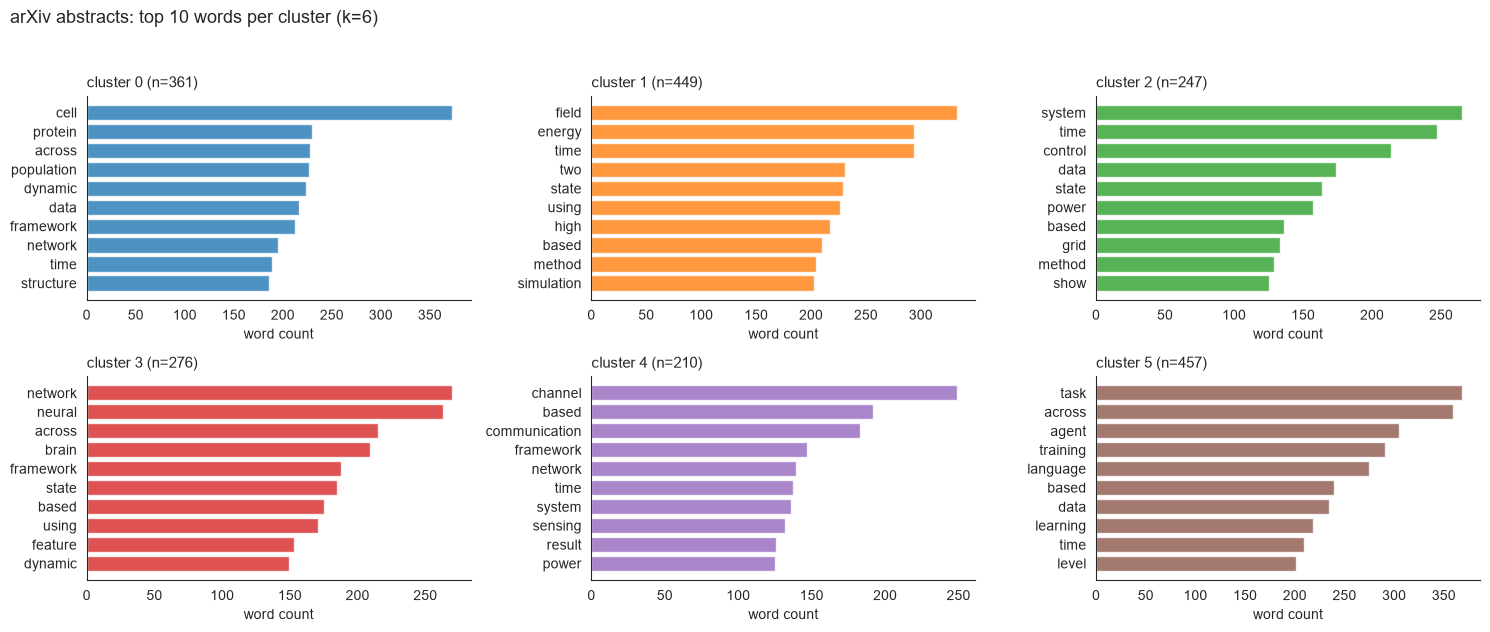

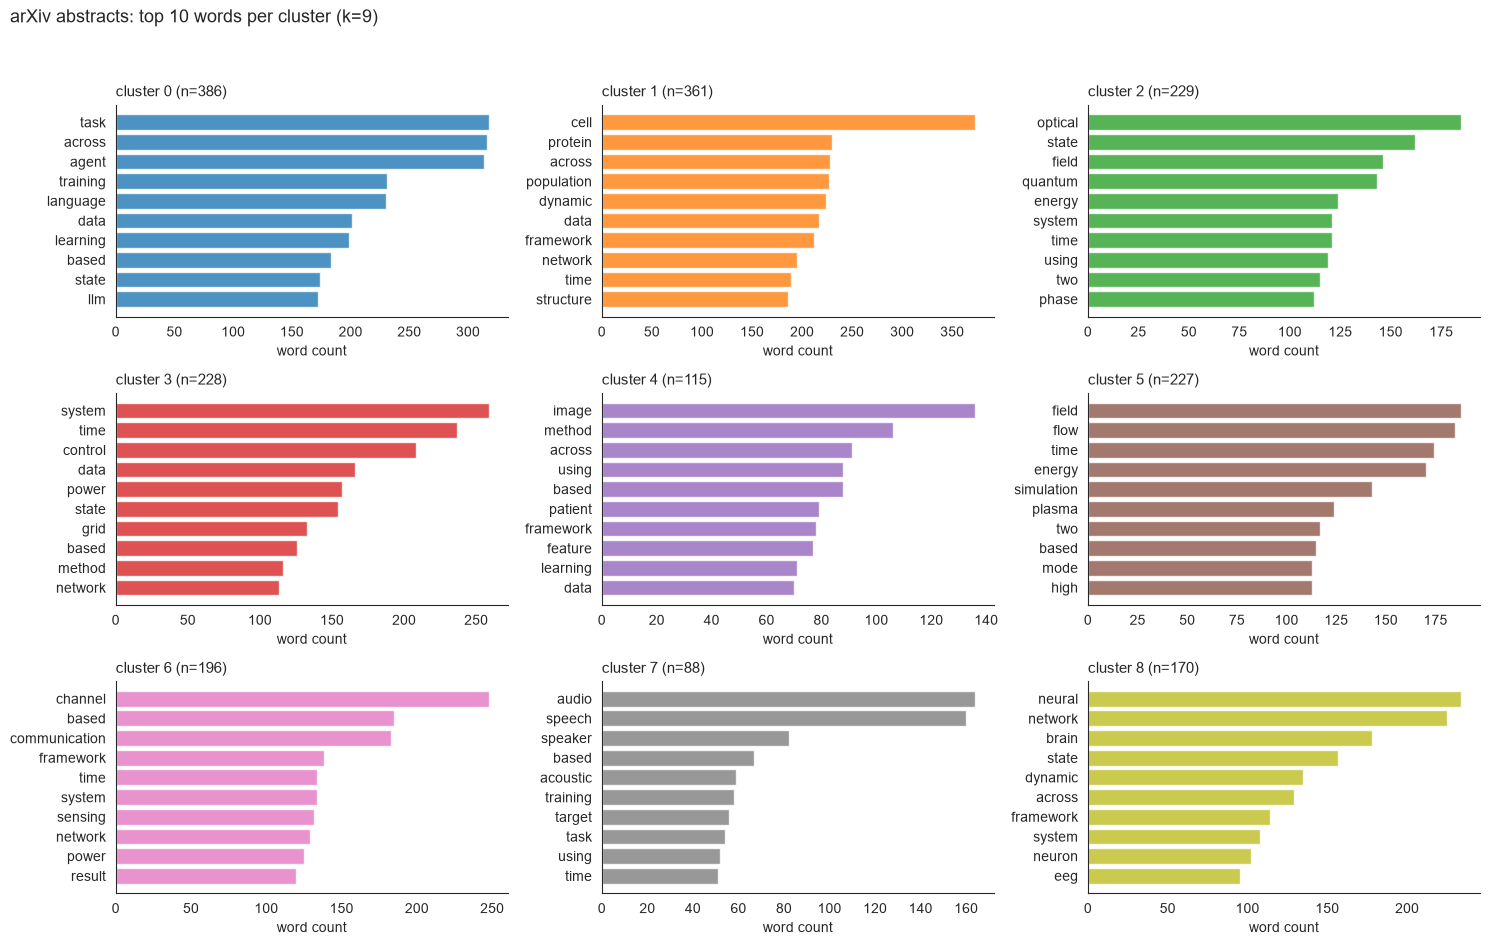

In [ ]:
for k in [6, 9]:
    df_k = pd.read_csv(f"../data/data_clustered_k{k}.csv")
    top = top_words_per_cluster(df_k, k)
    fig = plot_top_words(df_k, top, k)
    plt.show()

In [29]:
def top_words_per_cluster(df, k, text_col = TEXT_COL, n_top = N_TOP):
    texts = df[text_col].fillna("")

    vectorizer = TfidfVectorizer(min_df=5, max_df=0.5)
    X = vectorizer.fit_transform(texts)
    vocab = np.array(vectorizer.get_feature_names_out())

    labels = df["cluster"].to_numpy()
    result = {}
    for c in range(k):
        counts = np.asarray(X[labels == c].mean(axis=0)).ravel()
        idx = counts.argsort()[::-1][:n_top]
        result[c] = (vocab[idx], counts[idx])
    return result


def plot_top_words(df, top, k, n_cols=3):
    palette = sns.color_palette("tab10", n_colors=k)
    n_rows = int(np.ceil(k / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.2 * n_rows))
    axes = np.atleast_1d(axes).ravel()

    for c in range(k):
        words, counts = top[c]
        n_docs = (df["cluster"] == c).sum()
        axes[c].barh(words[::-1], counts[::-1], color=palette[c], alpha=0.8)
        axes[c].set_title(f"cluster {c} (n={n_docs})", loc="left", fontsize=11)
        axes[c].set_xlabel("word count")
        sns.despine(ax=axes[c])

    for ax in axes[k:]:
        ax.axis("off")

    fig.suptitle(f"arXiv abstracts: top {N_TOP} words per cluster (k={k})",
                 x=0.01, ha="left", fontsize=13)
    plt.tight_layout(rect=(0, 0, 1, 0.95))
    return fig

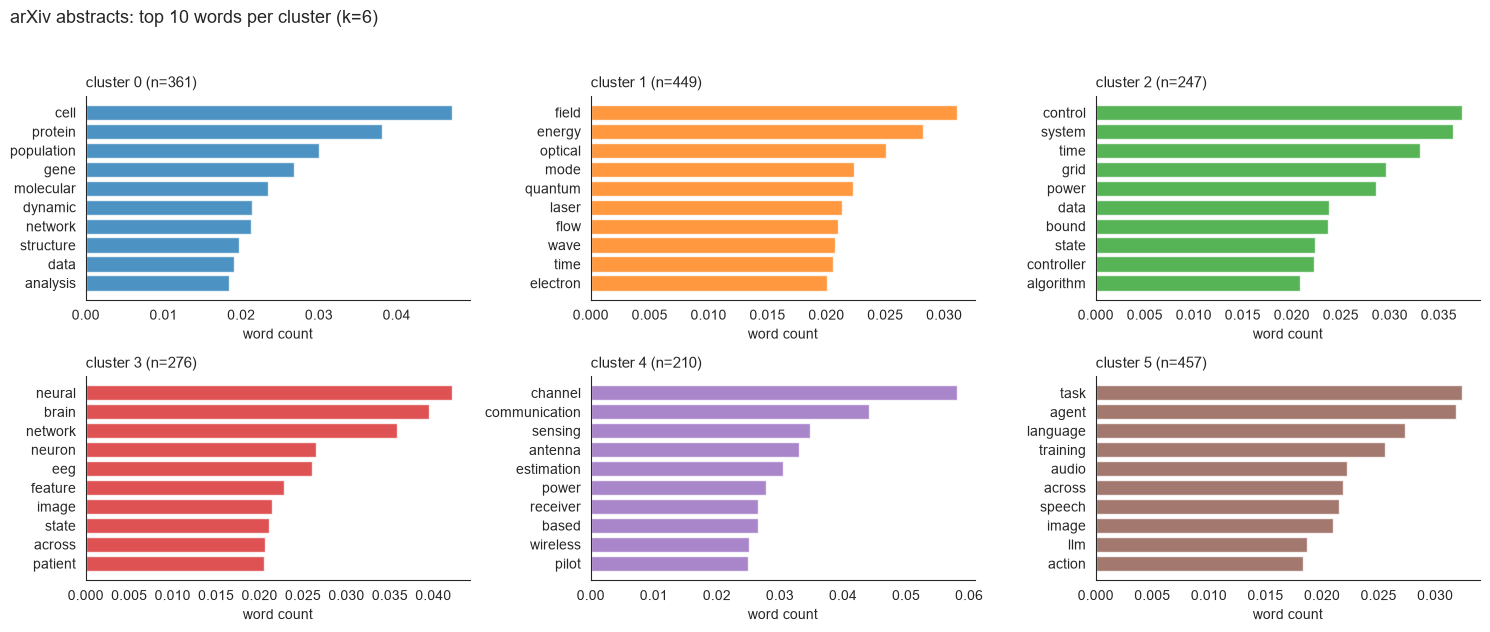

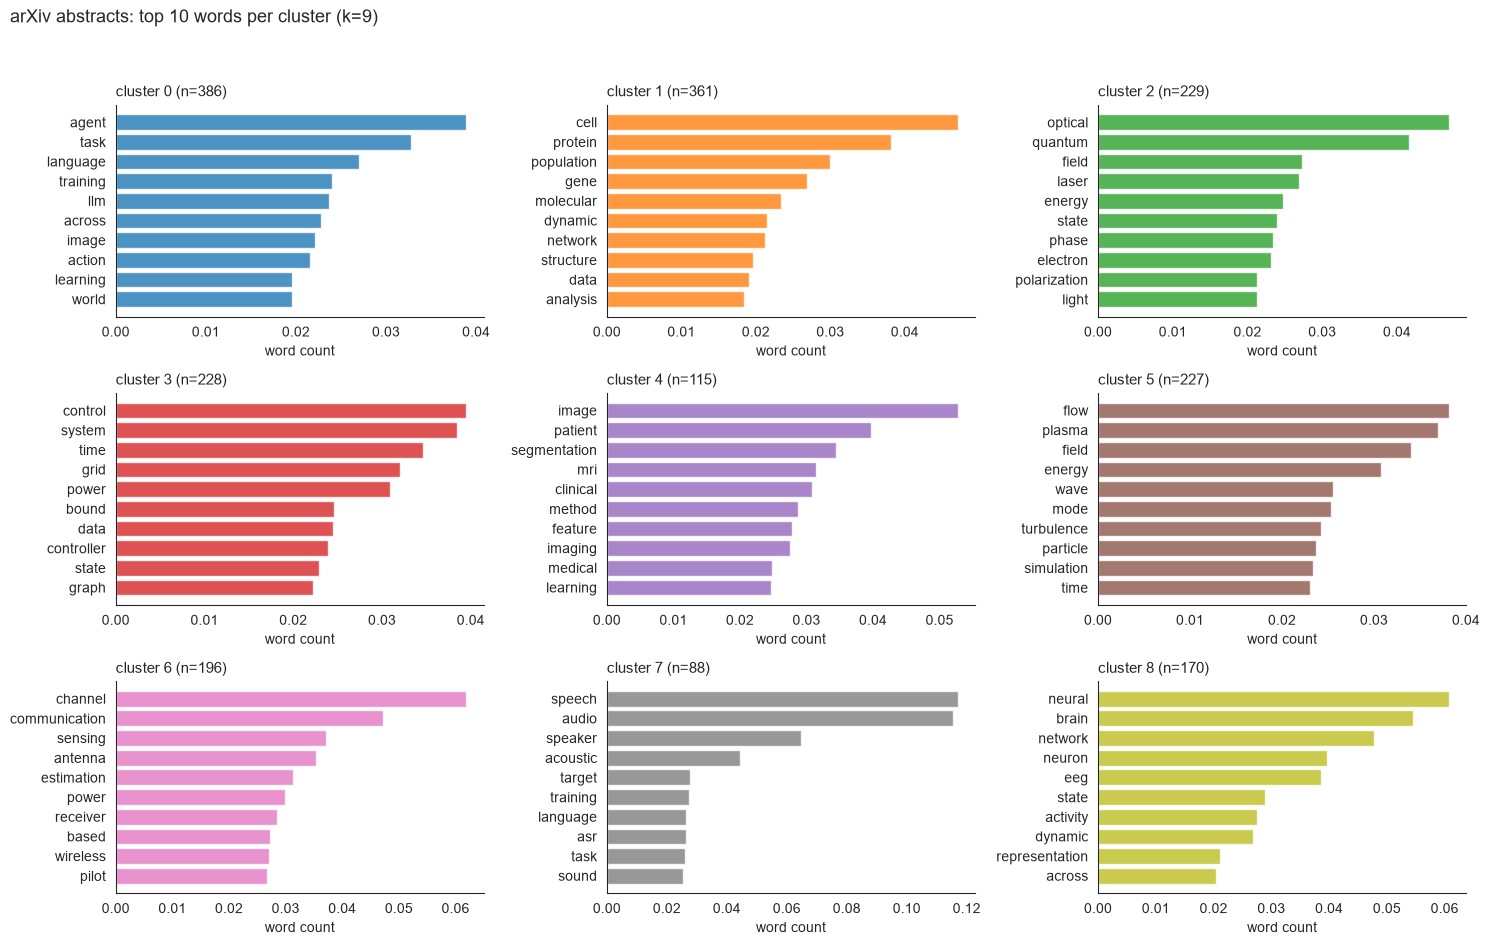

In [34]:
for k in [6, 9]:
    df_k = pd.read_csv(f"../data/data_clustered_k{k}.csv")
    top = top_words_per_cluster(df_k, k,)
    fig = plot_top_words(df_k, top, k)
    plt.show()

In [37]:
def cluster_weights(df, k, n_words=N_WORDS):
    texts = df[TEXT_COL].fillna("")
    vectorizer = TfidfVectorizer(min_df=5, max_df=0.5)
    X = vectorizer.fit_transform(texts)
    vocab = np.array(vectorizer.get_feature_names_out())
    labels = df["cluster"].to_numpy()

    weights = {}
    for c in range(k):
        scores = np.asarray(X[labels == c].mean(axis=0)).ravel()
        idx = scores.argsort()[::-1][:n_words]
        weights[c] = dict(zip(vocab[idx], scores[idx]))
    return weights


def plot_wordclouds(df, k, n_cols=3):
    weights = cluster_weights(df, k)
    n_rows = int(np.ceil(k / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows))
    axes = np.atleast_1d(axes).ravel()

    for c in range(k):
        wc = WordCloud(width=800, height=500, background_color="white",
                       colormap="viridis", max_words=N_WORDS,
                       prefer_horizontal=0.9, random_state=42)
        wc.generate_from_frequencies(weights[c])

        axes[c].imshow(wc, interpolation="bilinear")
        axes[c].set_title(f"cluster {c} (n={(df['cluster'] == c).sum()})",
                          loc="left", fontsize=11)
        axes[c].axis("off")

    for ax in axes[k:]:
        ax.axis("off")

    fig.suptitle(f"arXiv abstracts: word clouds per cluster (k={k})",
                 x=0.01, ha="left", fontsize=13)
    plt.tight_layout(rect=(0, 0, 1, 0.95))
    return fig

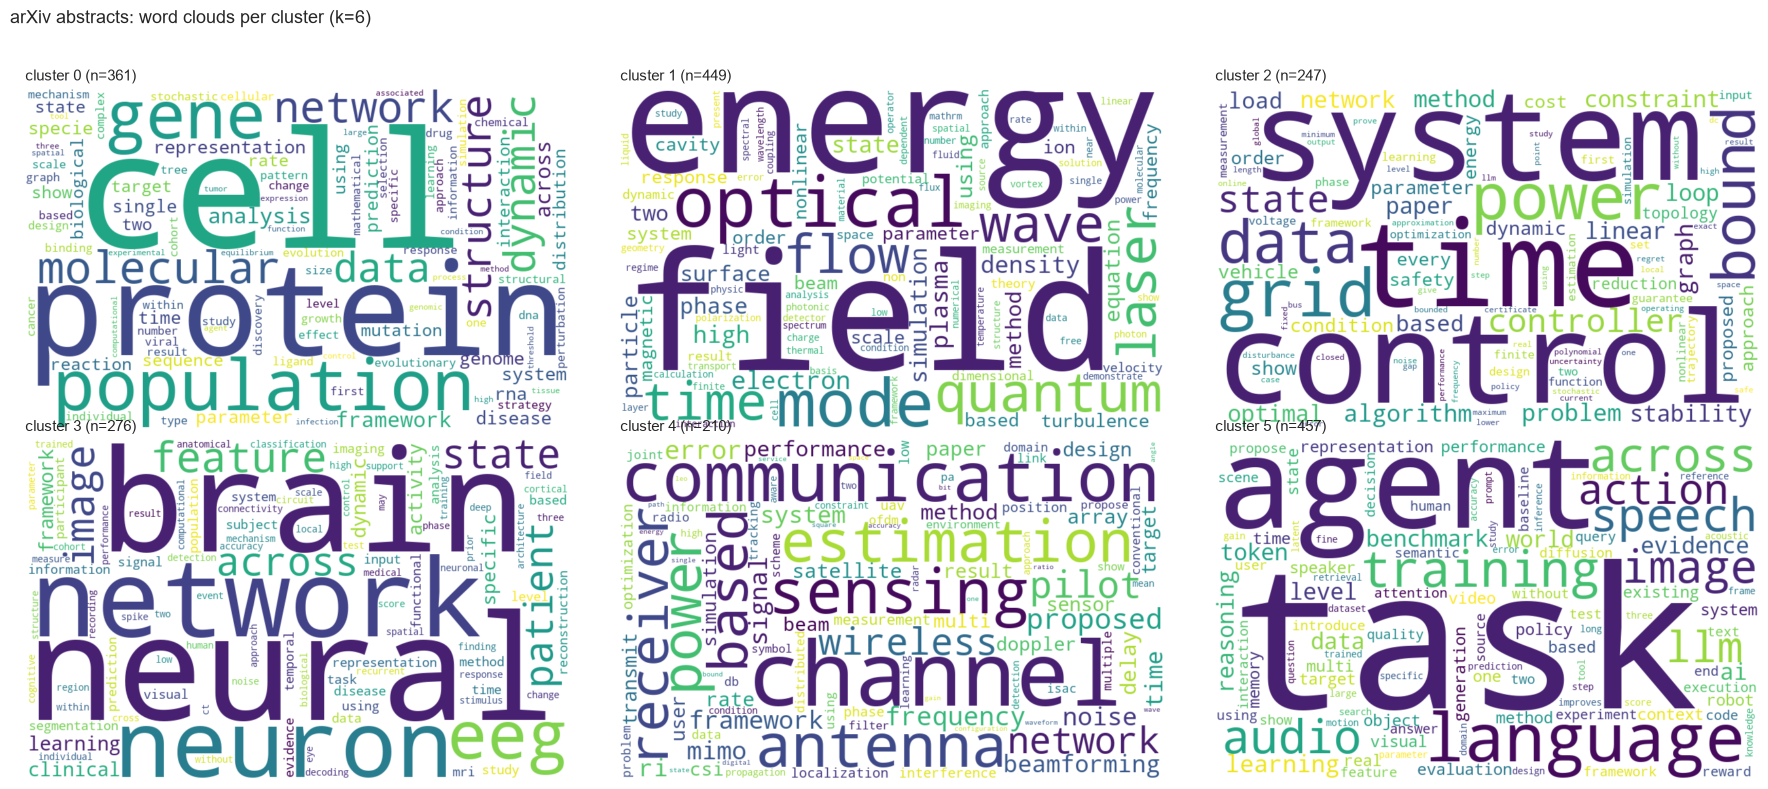

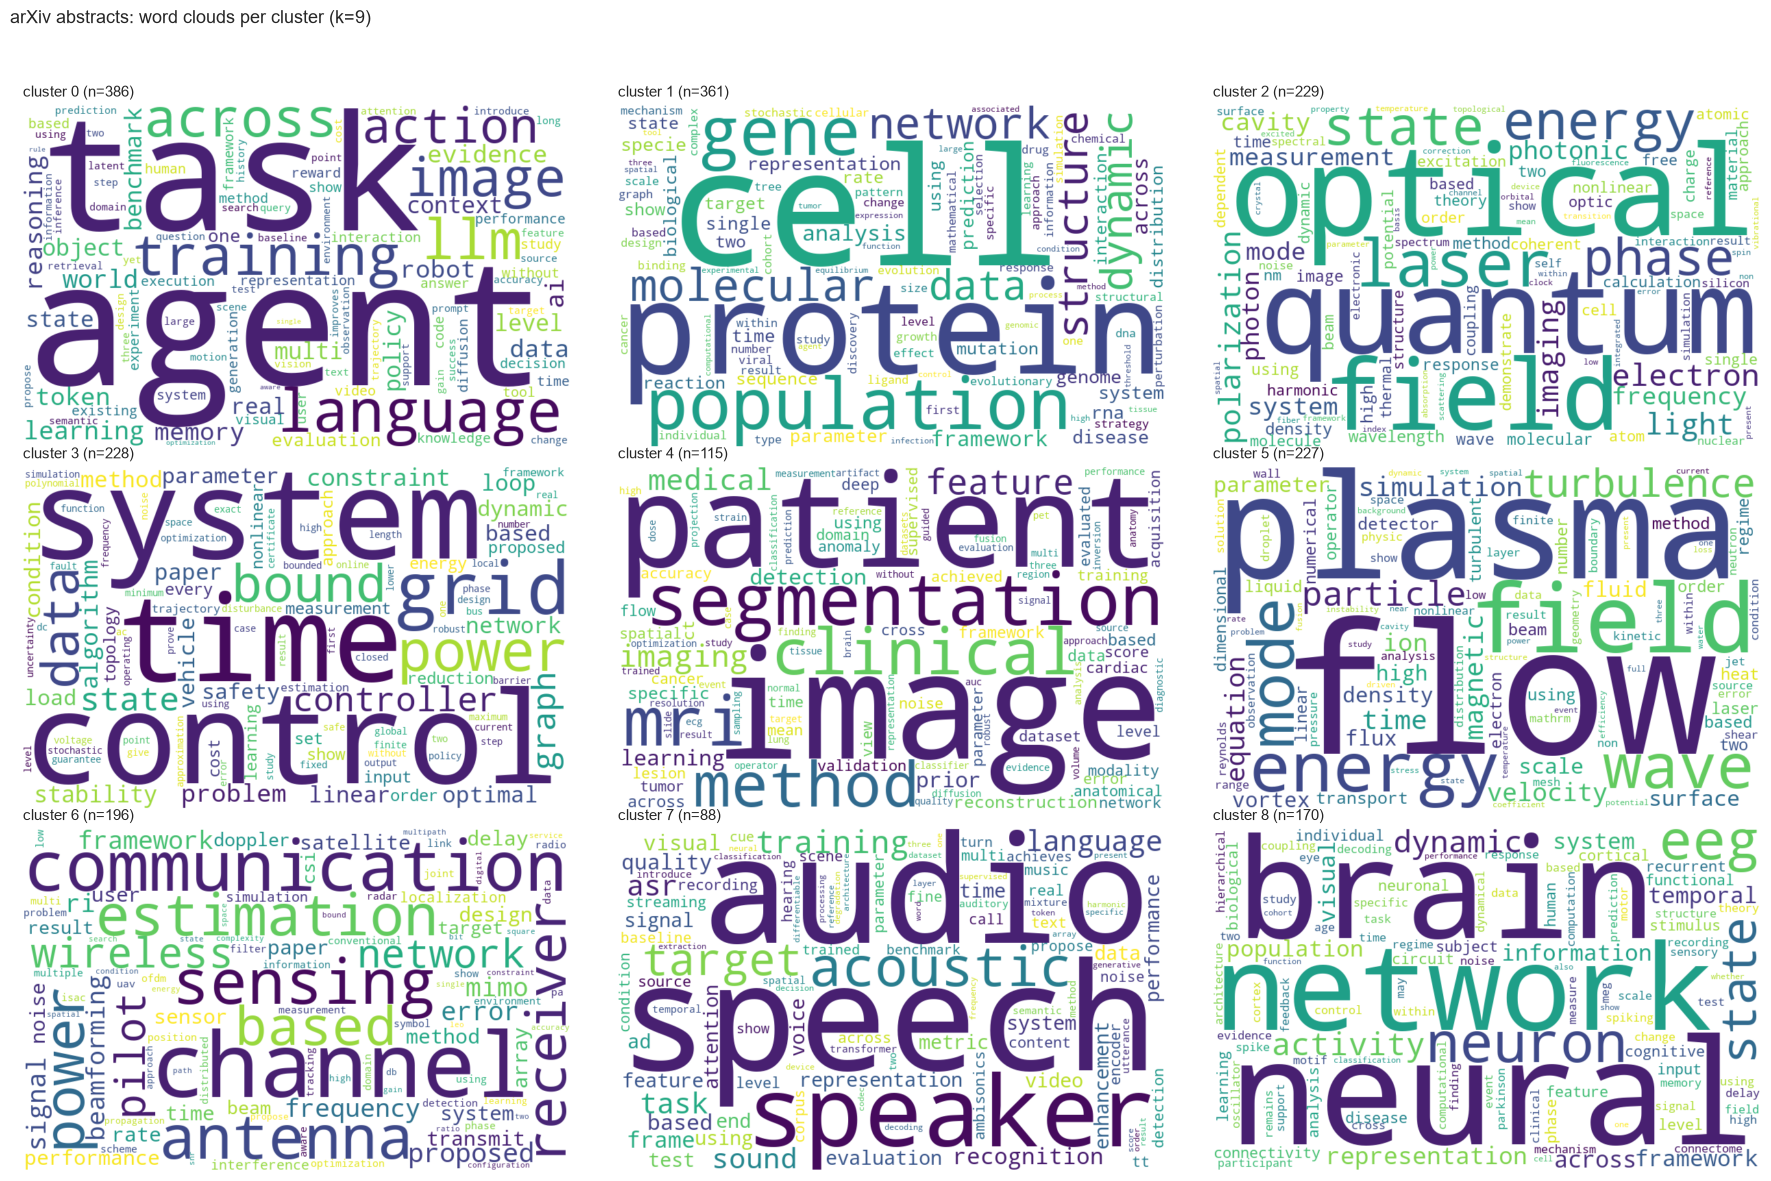

In [38]:
for k in [6, 9]:
    df_k = pd.read_csv(f"../data/data_clustered_k{k}.csv")
    fig = plot_wordclouds(df_k, k)
    plt.show()